In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:

df = pd.read_csv("lab_ticket_resolution.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (240, 6)


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [ ]:
print("DATA TYPES")
print(df.dtypes)

print("\nDESCRIPTIVE STATISTICS")
display(df.describe())

print("\nMISSING VALUES")
print(df.isna().sum())

print("\nFIRST FIVE ROWS")
display(df.head())

DATA TYPES
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

DESCRIPTIVE STATISTICS


,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,5.491667,54.820833,6.105417,0.233333,19.361125
std,2.979697,26.145017,3.391426,0.423836,10.035058
min,1.000000,1.000000,0.500000,0.000000,0.500000
25%,3.000000,33.000000,3.300000,0.000000,11.015000
50%,5.500000,54.000000,5.800000,0.000000,19.610000
75%,8.000000,74.000000,9.200000,0.000000,27.122500
max,10.000000,113.000000,12.000000,1.000000,42.500000



MISSING VALUES
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

FIRST FIVE ROWS


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04


In [ ]:
y = df["resolution_hours"]

X = df.drop(columns=["ticket_id", "resolution_hours"])

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

Feature matrix shape: (240, 4)
Target shape: (240,)

Features used:
['complexity_score', 'lines_changed', 'team_experience_years', 'reopened']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training features: (192, 3)
Test features: (48, 3)
Training target: (192,)
Test target: (48,)


In [ ]:
dummy = DummyRegressor(strategy="mean")

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_pred)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_pred))
dummy_r2 = r2_score(y_test, dummy_pred)

print("Dummy Regressor")
print("MAE:", dummy_mae)
print("RMSE:", dummy_rmse)
print("R2:", dummy_r2)

Dummy Regressor
MAE: 9.113951822916667
RMSE: 10.597684800766308
R2: -0.021016765260001957


In [ ]:
# Linear Regression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

Linear Regression
MAE: 2.5905403654464028
RMSE: 3.219152904435669
R2: 0.9057906326651207


In [ ]:
# Polynomial Regression - Degrees 2 and 3

# 5-fold cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

poly_results = {}

for degree in [2, 3]:
    poly_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    # Cross-validation using negative MAE
    cv_scores = cross_val_score(
        poly_model,
        X_train,
        y_train,
        cv=kf,
        scoring="neg_mean_absolute_error"
    )

    mean_cv_mae = -cv_scores.mean()

    # Fit on all training data
    poly_model.fit(X_train, y_train)

    # Test prediction
    poly_pred = poly_model.predict(X_test)

    test_mae = mean_absolute_error(y_test, poly_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
    test_r2 = r2_score(y_test, poly_pred)

    poly_results[degree] = {
        "CV MAE": mean_cv_mae,
        "Test MAE": test_mae,
        "Test RMSE": test_rmse,
        "Test R2": test_r2
    }

    print(f"\nPolynomial Regression - Degree {degree}")
    print("Cross-validation MAE:", mean_cv_mae)
    print("Test MAE:", test_mae)
    print("Test RMSE:", test_rmse)
    print("Test R2:", test_r2)


Polynomial Regression - Degree 2
Cross-validation MAE: 2.8674111825151853
Test MAE: 2.781772314755969
Test RMSE: 3.5528105428957666
Test R2: 0.8852493975607522

Polynomial Regression - Degree 3
Cross-validation MAE: 2.9810057077406378
Test MAE: 2.8233303022328893
Test RMSE: 3.62491811044292
Test R2: 0.8805441903044358


In [ ]:
# Ridge Regression

ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)

ridge_pred = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

print("Ridge Regression")
print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2:", ridge_r2)

Ridge Regression
MAE: 2.595372788194934
RMSE: 3.222239837006349
R2: 0.9056098662276617


In [ ]:
# Lasso Regression

lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.1)
)

lasso_model.fit(X_train, y_train)

lasso_pred = lasso_model.predict(X_test)

lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))
lasso_r2 = r2_score(y_test, lasso_pred)

print("Lasso Regression")
print("MAE:", lasso_mae)
print("RMSE:", lasso_rmse)
print("R2:", lasso_r2)

Lasso Regression
MAE: 2.606194041906993
RMSE: 3.227399101426122
R2: 0.9053073601769245


In [ ]:
# Final Model Comparison

results = pd.DataFrame({
    "Model": [
        "Dummy Regressor",
        "Linear Regression",
        "Polynomial Regression (Degree 2)",
        "Polynomial Regression (Degree 3)",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        dummy_mae,
        linear_mae,
        2.781772314755969,
        2.8233303022328893,
        ridge_mae,
        lasso_mae
    ],
    "RMSE": [
        dummy_rmse,
        linear_rmse,
        3.552810542895766,
        3.624918110444292,
        ridge_rmse,
        lasso_rmse
    ],
    "R2": [
        dummy_r2,
        linear_r2,
        0.8852493975607522,
        0.8805441903044358,
        ridge_r2,
        lasso_r2
    ]
})

display(results)

,Model,MAE,RMSE,R2
0,Dummy Regressor,9.113952,10.597685,-0.021017
1,Linear Regression,2.590540,3.219153,0.905791
2,Polynomial Regression (Degree 2),2.781772,3.552811,0.885249
3,Polynomial Regression (Degree 3),2.823330,3.624918,0.880544
4,Ridge Regression,2.595373,3.222240,0.905610
5,Lasso Regression,2.606194,3.227399,0.905307


## Evaluation summary

The regression models were compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

Linear Regression achieved the best overall performance, with an MAE of approximately 2.59, an RMSE of approximately 3.22, and an R² score of approximately 0.906. This means that the Linear Regression model explains about 90.6% of the variation in software support ticket resolution time.

Ridge Regression performed almost identically to Linear Regression, while Lasso Regression was slightly less accurate. The polynomial models performed worse than the linear model on the test data, suggesting that adding higher-degree polynomial terms did not improve prediction accuracy for this dataset.

The Dummy Regressor performed much worse than all other models, confirming that the regression models provide meaningful predictive information.

### Final Choice

Based on the test-set results, **Linear Regression is the preferred model** for predicting software support ticket resolution time because it has the lowest MAE and RMSE and the highest R² score among the tested models.

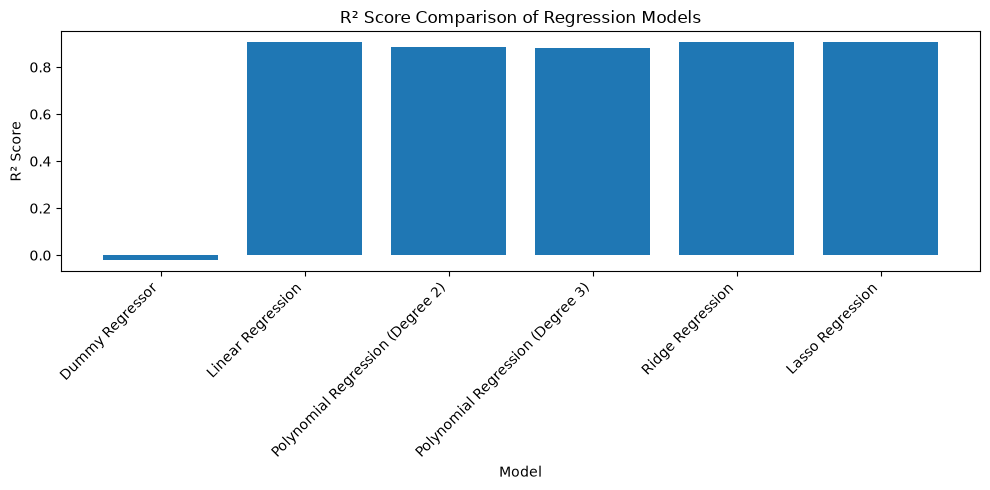

In [ ]:
import matplotlib.pyplot as plt

# Model comparison: R²
plt.figure(figsize=(10, 5))
plt.bar(results["Model"], results["R2"])
plt.ylabel("R² Score")
plt.xlabel("Model")
plt.title("R² Score Comparison of Regression Models")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

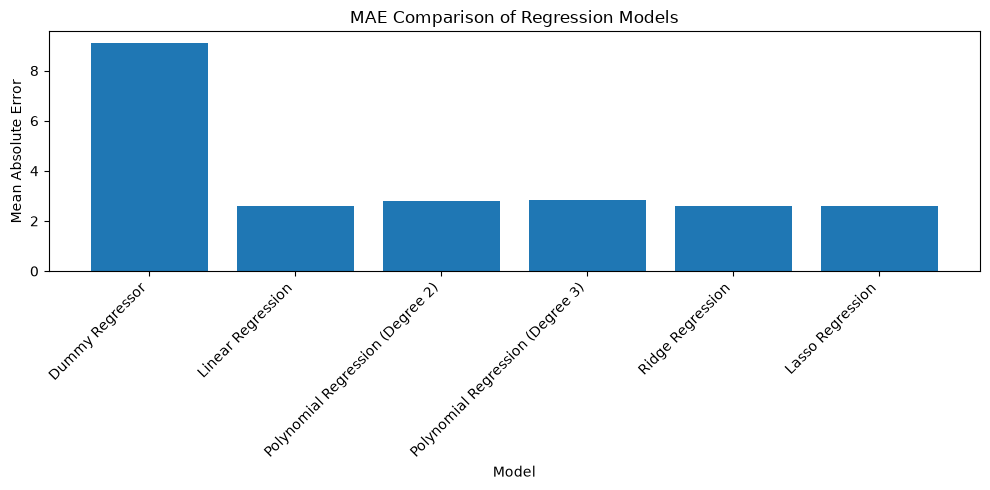

In [ ]:
# Model comparison: MAE
plt.figure(figsize=(10, 5))
plt.bar(results["Model"], results["MAE"])
plt.ylabel("Mean Absolute Error")
plt.xlabel("Model")
plt.title("MAE Comparison of Regression Models")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Model Comparison and Conclusion

The regression models were compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².

The results show that **Linear Regression performed the best overall**. It achieved the lowest MAE of approximately **2.59**, the lowest RMSE of approximately **3.22**, and an R² of approximately **0.906**.

Ridge Regression and Lasso Regression produced very similar results to Linear Regression. Polynomial Regression with degrees 2 and 3 performed slightly worse, while the Dummy Regressor performed substantially worse than all other models.

Therefore, **Linear Regression is the preferred model for predicting ticket resolution time in this dataset**. Its high R² indicates that the model explains about **90.6% of the variation** in the target variable.

### Final Conclusion

Among the tested models, Linear Regression provides the best balance of accuracy and simplicity. The results suggest that the selected features have a strong relationship with ticket resolution time. However, model performance should still be evaluated on new, unseen data before using the model for real-world predictions.

In [ ]:
# Example prediction using the best model

best_model = linear_model

# Predict the test set
final_predictions = best_model.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted values:")
print(final_predictions[:10])

First 10 actual values:
[20.62 22.8   7.19  5.97 25.98  4.74 12.12 28.02 28.8  35.55]

First 10 predicted values:
[12.75830864 22.15292197  4.88034002  4.53834159 21.36647862  6.78443365
 13.02080979 29.44964629 28.04745272 32.77888271]


In [ ]:
# Final model evaluation

print("Final Model: Linear Regression")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R²:", linear_r2)

Final Model: Linear Regression
MAE: 2.5905403654464028
RMSE: 3.219152904435669
R²: 0.9057906326651207


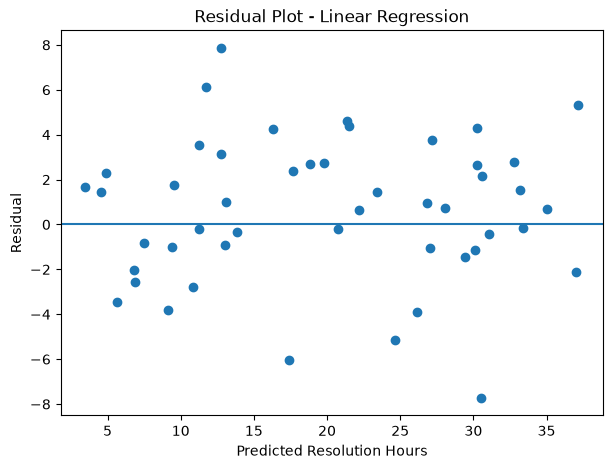

In [ ]:
# Residual plot - Linear Regression

linear_residuals = y_test - linear_pred

plt.figure(figsize=(7, 5))
plt.scatter(linear_pred, linear_residuals)

plt.axhline(0)

plt.xlabel("Predicted Resolution Hours")
plt.ylabel("Residual")
plt.title("Residual Plot - Linear Regression")

plt.show()

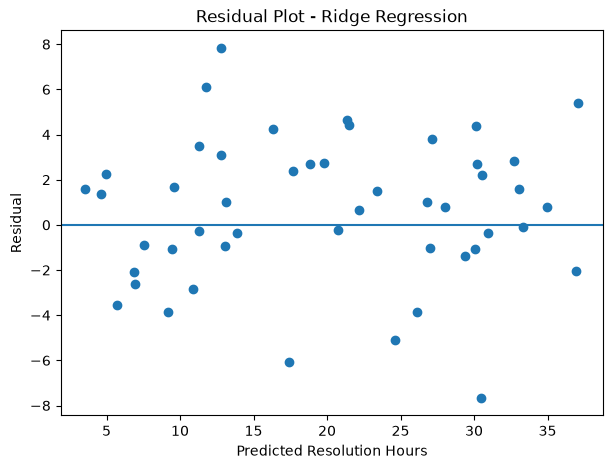

In [ ]:
# Residual plot - Ridge Regression

ridge_residuals = y_test - ridge_pred

plt.figure(figsize=(7, 5))
plt.scatter(ridge_pred, ridge_residuals)

plt.axhline(0)

plt.xlabel("Predicted Resolution Hours")
plt.ylabel("Residual")
plt.title("Residual Plot - Ridge Regression")

plt.show()

## Residual Plot Insights

We checked the residual plots to see if our models were making predictable mistakes. Ideally, errors should be scattered randomly around zero with no distinct patterns.

Model Performance: For both Linear and Ridge Regression, the errors are evenly spread around zero with no curved patterns. A few individual tickets had larger errors, which likely means those particular tickets were just harder to predict.

Error Spread: The spread of errors stays consistent across the board, meaning the model's accuracy doesn't wildly change for longer or shorter resolution times.

Note of Caution: Because the dataset is small and artificial, we should take these diagnostic results with a grain of salt.


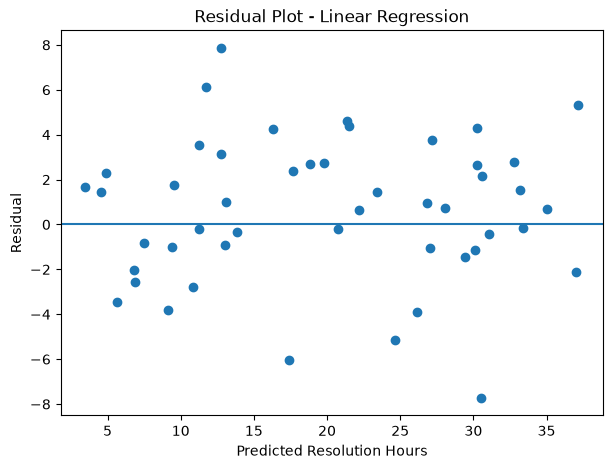

In [ ]:
# Residual plot - Linear Regression

linear_residuals = y_test - linear_pred

plt.figure(figsize=(7, 5))
plt.scatter(linear_pred, linear_residuals)

plt.axhline(0)

plt.xlabel("Predicted Resolution Hours")
plt.ylabel("Residual")
plt.title("Residual Plot - Linear Regression")

plt.show()

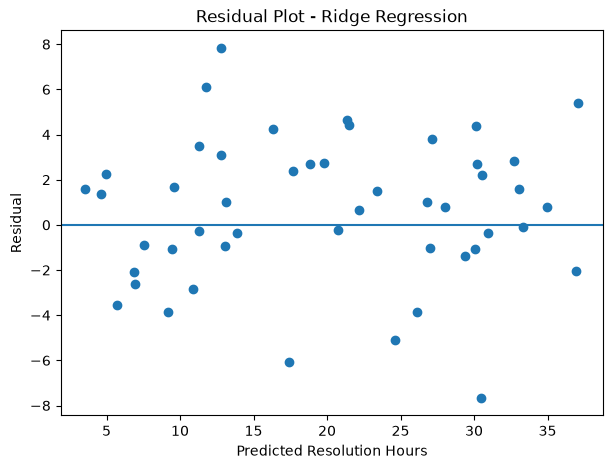

In [ ]:
# Residual plot - Ridge Regression

ridge_residuals = y_test - ridge_pred

plt.figure(figsize=(7, 5))
plt.scatter(ridge_pred, ridge_residuals)

plt.axhline(0)

plt.xlabel("Predicted Resolution Hours")
plt.ylabel("Residual")
plt.title("Residual Plot - Ridge Regression")

plt.show()

## Analysis Questions

### 10. Why is the mean baseline useful even though it ignores all features?

 It gives a simple starting point for evaluating the other models. It predicts the average resolution time for every ticket without using any features. If a regression model cannot perform better than this simple baseline, then the model is not extracting useful predictive information from the available features.

### 11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?

Linear Regression has the lowest MAE, at approximately **2.59 hours**, and also the lowest RMSE, at approximately **3.22 hours**. Therefore, the same model has the lowest MAE and RMSE in this experiment.

MAE and RMSE can sometimes select different models because they measure errors differently. MAE treats errors more evenly, while RMSE gives greater importance to large errors because the errors are squared. Therefore, a model with a few very large prediction errors may have a substantially higher RMSE even if its MAE is relatively good.

### 12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?

Polynomial features did not improve the final test performance compared with Linear Regression. The degree 2 polynomial model had an R² of approximately **0.885**, while degree 3 had an R² of approximately **0.881**. Both were lower than Linear Regression's R² of approximately **0.906**.

The higher-degree model was more complex but performed worse on the test data. This suggests that increasing polynomial complexity was not useful for this dataset. A difference between training performance and cross-validation or test performance would provide stronger evidence of overfitting.

### 13. How did regularization affect performance and coefficient magnitudes?

Ridge and Lasso produced results very close to ordinary Linear Regression. Ridge had an MAE of approximately **2.60**, RMSE of approximately **3.22**, and R² of approximately **0.906**. Lasso had an MAE of approximately **2.61**, RMSE of approximately **3.23**, and R² of approximately **0.905**.

Regularization reduces the magnitude of model coefficients. Ridge generally shrinks coefficients toward zero without removing them completely, while Lasso can shrink some coefficients to exactly zero. In this dataset, regularization did not produce a meaningful improvement over ordinary Linear Regression.

### 14. Why is scaling included in the Ridge/Lasso pipeline?

Scaling is important because Ridge and Lasso penalize the size of model coefficients. If features have very different numerical scales, the regularization penalty may affect them unevenly.

StandardScaler puts the features on a comparable scale before regularization is applied. Keeping the scaler inside the pipeline also ensures that scaling is performed correctly during cross-validation without using information from the validation or test data.

### 15. Identify one potential leakage issue in the dataset and explain how you handled it.

The `lines_changed` feature is a potential leakage risk. If the goal is to predict resolution time when a ticket is initially received, the eventual number of lines changed may not yet be known. Using it could provide the model with information that becomes available during or after the resolution process.

Therefore, `ticket_id` was excluded because it is only an identifier, and `lines_changed` should be excluded from the main prediction model when predicting at ticket creation time.

### 16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams?

A random split may not be appropriate if tickets were collected over several years because it could allow information from future periods to appear in the training data while older tickets are placed in the test data.

Similarly, if the same customers or teams appear repeatedly, a random split could place tickets from the same customer or team in both training and test sets. This could make the model appear more accurate than it would be for genuinely new customers or teams.

For time-dependent data, a time-based split would be more appropriate. For repeated customers or teams, group-based splitting or group cross-validation would provide a more realistic evaluation.

### 17. What additional tests would you perform before deploying this model?

Before deployment, I would:

1. Test the model on a larger and more realistic historical dataset.
2. Use a time-based test set if tickets are collected over time.
3. Check performance separately across different teams, customers, and ticket complexity levels.
4. Investigate tickets that produce unusually large prediction errors.
5. Check carefully for additional data leakage.
6. Confirm that all model features are actually available at prediction time.
7. Monitor model performance after deployment to detect changes in the ticket-resolution process.
8. Compare the model with a simple operational baseline to determine whether it provides useful practical value.

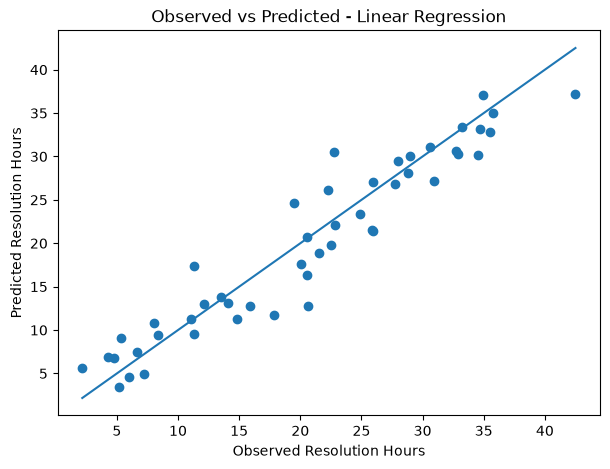

In [ ]:
# Observed vs Predicted - Linear Regression

plt.figure(figsize=(7, 5))
plt.scatter(y_test, linear_pred)

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Observed Resolution Hours")
plt.ylabel("Predicted Resolution Hours")
plt.title("Observed vs Predicted - Linear Regression")

plt.show()

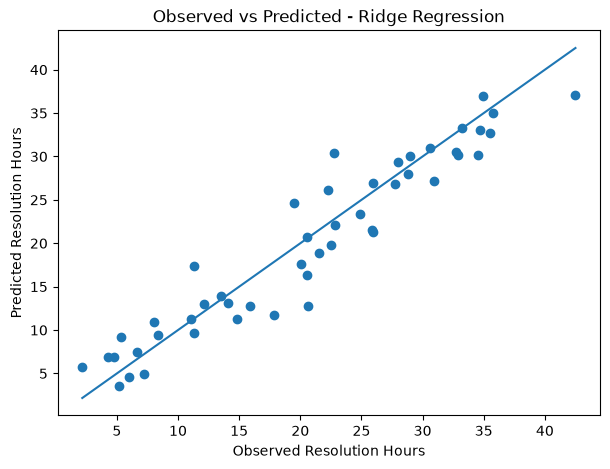

In [ ]:
# Observed vs Predicted - Ridge Regression

plt.figure(figsize=(7, 5))
plt.scatter(y_test, ridge_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.xlabel("Observed Resolution Hours")
plt.ylabel("Predicted Resolution Hours")
plt.title("Observed vs Predicted - Ridge Regression")

plt.show()


There are several limitations that should be considered before using this model in a real software support environment.

1. **Synthetic data limitation:** The dataset is synthetic, so its relationships may not accurately represent real-world support tickets. Performance on this dataset does not guarantee the same performance in a real organization.

2. **Potential data leakage:** `lines_changed` may not be available when a ticket is first received. Using information that becomes available only during or after resolution could make the model appear more accurate than it would be in real use.

3. **Limited dataset size:** The dataset contains only 240 tickets. A larger and more diverse dataset would be needed to determine whether the observed relationships generalize to new tickets.

4. **Changing processes:** Software teams, tools, workloads, and support procedures can change over time. A model trained on historical tickets may become less accurate as these conditions change.

5. **Unusual tickets:** Some tickets may be unusually difficult or have very long resolution times. These influential observations should be investigated because they can have a large effect on regression models and error metrics.

Before deployment, the model should therefore be tested on additional real-world data, evaluated using a time-based validation strategy where appropriate, checked for leakage, and monitored for changes in predictive performance.